# VisionGPT-2 Image Captioning — improved

Based on an existing public Kaggle notebook (ViT encoder + GPT-2 decoder with added cross-attention).
**Original notebook:** _https://www.kaggle.com/code/shreydan/visiongpt2-image-captioning-pytorch_. The model architecture and the training schedule are theirs; the changes below are mine.

## What changed and why

| # | Change | Why it matters |
|---|---|---|
| 1 | **Validate on the official COCO `val2017` split** instead of a random split of caption rows | COCO has ~5 captions per image. Splitting by caption put the same images in both train and validation, so the original validation perplexity was optimistic. |
| 2 | **Fixed the training/generation mismatch for the first word.** Training sequences are now `[BOS] caption [EOS]` | The original trained on `caption [EOS]` but generated starting from `[BOS]`. The model never learned to predict the first word, and every token sat one position off from where it was trained. |
| 3 | **Encoder caching + KV cache in generation** | The original re-ran all 12 ViT blocks and the whole decoder for every generated token. Now the image is encoded once and past keys/values are reused. Same captions, much less compute. |
| 4 | **Beam search** (plus batched greedy decoding) | The original only had sampling or greedy decoding, one image at a time. |
| 5 | **BLEU-1/4 and CIDEr evaluation** (`pycocoevalcap`) | Perplexity alone doesn't tell you how good the captions are. CIDEr is the standard captioning metric. |
| 6 | **Checkpoint selected by validation CIDEr**, checkpoint saved every epoch, resume support, Kaggle time guard | The best-perplexity epoch is not always the best-caption epoch; long runs can survive a session timeout. |
| 7 | Smaller fixes: `autocast` now wraps only the forward pass; removed horizontal-flip augmentation (it contradicts captions with "left"/"right"); removed the ignored `always_apply` argument | Correctness / hygiene. |

The module and parameter names are unchanged, so **a checkpoint from the original notebook loads directly** into this model (see section 6).

## Experiment plan
Every result is appended to `/kaggle/working/results.csv`.

| ID | What | Needs training? |
|---|---|---|
| E0 | Original checkpoint, greedy, scored on val2017 | No (needs the original `captioner.pt`) |
| E1 | Original checkpoint + beam search | No |
| E2 | Original checkpoint: naive vs cached decoding speed (GPU and CPU) | No |
| E3 | Retrain with fixes, `MODE='compare'` (same budget as original: 150k captions, 5 epochs) | Yes |
| E4 | Final model, `MODE='full'` (all ~590k train captions) | Yes |

Keep the budget fixed (`compare`) when comparing changes, otherwise you can't tell whether the method or the extra training made the difference.

**Kaggle settings:** GPU accelerator, Internet ON (for `pip install` and pretrained weights), input dataset `awsaf49/coco-2017-dataset`.

In [1]:
!pip install -q pycocoevalcap

In [2]:
import os, re, io, json, math, time, random, gc, shutil, contextlib
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from timm import create_model
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
from tqdm.auto import tqdm

os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# 1. Configuration

In [3]:
MODE = 'compare'          # 'compare' = original budget (150k captions, 5 epochs); 'full' = all train2017 captions
EXP_NAME = 'E3_fixed_compare' if MODE == 'compare' else 'E4_full'

cfg = SimpleNamespace(
    data_root = Path('/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017'),
    n_train_captions = 150_000 if MODE == 'compare' else None,   # None = use all
    epochs = 5 if MODE == 'compare' else 8,
    freeze_epochs_gpt = 1,      # epoch 0: only cross-attention trains
    freeze_epochs_all = 2,      # epoch 1: + GPT-2; epoch 2+: everything incl. ViT
    lr = 1e-4,
    batch_size = 32,
    num_workers = 4,
    max_caption_tokens = 64,
    use_hflip = False,
    n_eval_images_per_epoch = 1000,   # val images scored with CIDEr after each epoch (full 5k at the end)
    select_by = 'cider',              # 'cider' or 'val_loss'
    beam_size = 3,
    length_penalty = 1.0,             # beam score = logprob / length**length_penalty
    max_gen_tokens = 30,
    max_hours = 11.0,                 # stop before Kaggle's 12h session limit; resume in a new session
    resume_from = None,               # e.g. Path('/kaggle/input/my-previous-run/run_E4_full/last.pt')
    out_dir = Path(f'/kaggle/working/run_{EXP_NAME}'),
    results_csv = Path('/kaggle/working/results.csv'),
    seed = 42,
    device = 'cuda' if torch.cuda.is_available() else 'cpu',
)

model_config = SimpleNamespace(
    vocab_size = 50_257,
    embed_dim = 768,
    num_heads = 12,
    seq_len = 1024,
    depth = 12,
    attention_dropout = 0.1,
    residual_dropout = 0.1,
    mlp_ratio = 4,
    mlp_dropout = 0.1,
    emb_dropout = 0.1,
)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(cfg.seed)
cfg.out_dir.mkdir(parents=True, exist_ok=True)

def autocast_ctx():
    # fp16 mixed precision on GPU only; wraps the forward pass, never the backward/optimizer step
    return torch.autocast(device_type=cfg.device, dtype=torch.float16, enabled=(cfg.device == 'cuda'))

def log_result(**row):
    row = {'time': time.strftime('%Y-%m-%d %H:%M'), **row}
    df = pd.read_csv(cfg.results_csv) if cfg.results_csv.exists() else pd.DataFrame()
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(cfg.results_csv, index=False)
    return df

# 2. Data
Training uses COCO `train2017` captions; validation uses the official `val2017` split (5,000 images, ~25k captions), so no image appears in both.

In [4]:
tokenizer = GPT2TokenizerFast.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token
BOS = EOS = tokenizer.eos_token_id    # GPT-2 uses <|endoftext|> (50256) as both BOS and EOS

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [5]:
def load_coco(split):
    with open(cfg.data_root / 'annotations' / f'captions_{split}2017.json') as f:
        ann = json.load(f)['annotations']
    df = pd.DataFrame([(a['image_id'], a['caption'].strip()) for a in ann], columns=['image_id', 'caption'])
    df['image'] = df['image_id'].map(lambda i: cfg.data_root / f'{split}2017' / f'{i:012d}.jpg')
    return df

train_df = load_coco('train')
val_df = load_coco('val')
if cfg.n_train_captions:
    train_df = train_df.sample(cfg.n_train_captions, random_state=cfg.seed)
train_df = train_df.reset_index(drop=True)

assert not set(train_df.image_id) & set(val_df.image_id), 'train/val image overlap!'

val_refs = val_df.groupby('image_id')['caption'].apply(list).to_dict()     # image_id -> all reference captions
val_id2path = dict(zip(val_df.image_id, val_df.image))
all_val_ids = sorted(val_refs)
eval_ids = sorted(random.Random(cfg.seed).sample(all_val_ids, min(cfg.n_eval_images_per_epoch, len(all_val_ids))))

print(f'train: {len(train_df):,} captions / {train_df.image_id.nunique():,} images')
print(f'val:   {len(val_df):,} captions / {len(val_refs):,} images  (per-epoch CIDEr on {len(eval_ids)})')

train: 150,000 captions / 90,924 images
val:   25,014 captions / 5,000 images  (per-epoch CIDEr on 1000)


In [6]:
aug = [
    A.RandomBrightnessContrast(),
    A.ColorJitter(),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.3, rotate_limit=45, p=0.5),
    A.HueSaturationValue(p=0.3),
]
if cfg.use_hflip:
    aug.insert(0, A.HorizontalFlip())   # off by default: flipping breaks captions that mention left/right
base = [A.Resize(224, 224), A.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]), ToTensorV2()]
train_tfms = A.Compose(aug + base)
valid_tfms = A.Compose(base)

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [7]:
class CaptionDataset(torch.utils.data.Dataset):
    # Each sample is [BOS] caption [EOS]; the model sees seq[:-1] and predicts seq[1:].
    # (The original fed `caption [EOS]` without BOS, so the first word was never a training target.)
    def __init__(self, df, tfms, max_len=64):
        self.df, self.tfms, self.max_len = df.reset_index(drop=True), tfms, max_len
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = np.array(Image.open(row['image']).convert('RGB'))
        image = self.tfms(image=image)['image']
        ids = tokenizer(row['caption'], truncation=True, max_length=self.max_len)['input_ids']
        seq = [BOS] + ids + [EOS]
        return image, seq[:-1], seq[1:]

def collate_fn(batch):
    # dynamic padding; padding is marked by length (not by token id, since BOS == EOS == pad in GPT-2)
    images = torch.stack([b[0] for b in batch])
    L = max(len(b[1]) for b in batch)
    input_ids = torch.full((len(batch), L), EOS, dtype=torch.long)
    labels = torch.full((len(batch), L), -100, dtype=torch.long)     # -100 is ignored by cross-entropy
    for i, (_, x, y) in enumerate(batch):
        input_ids[i, :len(x)] = torch.tensor(x)
        labels[i, :len(y)] = torch.tensor(y)
    return images, input_ids, labels

class ImageDataset(torch.utils.data.Dataset):
    # images only, for caption generation / evaluation
    def __init__(self, image_ids, id2path, tfms):
        self.ids, self.id2path, self.tfms = list(image_ids), id2path, tfms
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, idx):
        i = self.ids[idx]
        image = np.array(Image.open(self.id2path[i]).convert('RGB'))
        return self.tfms(image=image)['image'], i

In [8]:
train_ds = CaptionDataset(train_df, train_tfms, cfg.max_caption_tokens)
val_ds = CaptionDataset(val_df, valid_tfms, cfg.max_caption_tokens)
dl_kw = dict(batch_size=cfg.batch_size, num_workers=cfg.num_workers, pin_memory=True,
             persistent_workers=cfg.num_workers > 0, collate_fn=collate_fn)
train_dl = torch.utils.data.DataLoader(train_ds, shuffle=True, drop_last=True, **dl_kw)
val_dl = torch.utils.data.DataLoader(val_ds, shuffle=False, **dl_kw)

images, x, y = next(iter(torch.utils.data.DataLoader(train_ds, batch_size=2, collate_fn=collate_fn)))
print('input :', x[0].tolist())
print('labels:', y[0].tolist())

input : [50256, 7571, 1862, 1450, 5586, 319, 257, 7624, 290, 257, 10846, 5055, 1306, 284, 606, 50256, 50256, 50256, 50256]
labels: [7571, 1862, 1450, 5586, 319, 257, 7624, 290, 257, 10846, 5055, 1306, 284, 606, 50256, -100, -100, -100, -100]


# 3. Model
Same architecture and parameter names as the original (so its checkpoints load), with two changes inside:

- **Attention returns its keys/values** so generation can reuse them (KV cache). Uses `F.scaled_dot_product_attention`, which is mathematically the same as the original softmax(QKᵀ/√d)V and uses fused kernels on GPU.
- **`forward` is split into `encode` and `decode`.** Decoder block *i* only reads the output of ViT block *i*, and the ViT never reads the decoder, so running all 12 ViT blocks first gives exactly the same result as the original interleaved loop — but lets generation encode the image **once**.

In [9]:
class GPT2Attention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.embed_dim = config.embed_dim
        self.n_heads = config.num_heads
        assert self.embed_dim % self.n_heads == 0, 'embedding dimension must be divisible by number of heads'
        self.head_size = self.embed_dim // self.n_heads
        self.seq_len = config.seq_len
        self.c_attn = nn.Linear(self.embed_dim, self.head_size * self.n_heads * 3, bias=True)
        self.c_proj = nn.Linear(self.embed_dim, self.embed_dim, bias=True)
        self.attn_dropout = nn.Dropout(config.attention_dropout)
        self.resid_dropout = nn.Dropout(config.residual_dropout)
        # unused now (SDPA handles causality); kept so checkpoints from the original notebook load with strict=True
        self.register_buffer('mask', torch.tril(torch.ones(1, 1, self.seq_len, self.seq_len)))

    def _heads(self, z, b, t):
        return z.view(b, t, self.n_heads, self.head_size).transpose(1, 2)    # b x heads x t x head_size

    def forward(self, x, past=None):
        b, t, c = x.shape
        q, k, v = self.c_attn(x).split(self.embed_dim, dim=-1)
        q, k, v = self._heads(q, b, t), self._heads(k, b, t), self._heads(v, b, t)
        if past is not None:
            assert t == 1, 'with a KV cache, feed one new token at a time'
            k = torch.cat([past[0], k], dim=2)
            v = torch.cat([past[1], v], dim=2)
        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
            is_causal=(past is None and t > 1),
        )
        y = y.transpose(1, 2).contiguous().view(b, t, c)
        return self.resid_dropout(self.c_proj(y)), (k, v)


class GPT2CrossAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.embed_dim = config.embed_dim
        self.n_heads = config.num_heads
        assert self.embed_dim % self.n_heads == 0, 'embedding dimension must be divisible by number of heads'
        self.head_size = self.embed_dim // self.n_heads
        self.q = nn.Linear(self.embed_dim, self.embed_dim)
        self.k = nn.Linear(self.embed_dim, self.embed_dim)
        self.v = nn.Linear(self.embed_dim, self.embed_dim)
        self.c_proj = nn.Linear(self.embed_dim, self.embed_dim, bias=True)
        self.attn_dropout = nn.Dropout(config.attention_dropout)
        self.resid_dropout = nn.Dropout(config.residual_dropout)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)    # GPT-2 init trick from the original
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)

    def _heads(self, z):
        b, t, _ = z.shape
        return z.view(b, t, self.n_heads, self.head_size).transpose(1, 2)

    def forward(self, x, enc, kv=None):
        # kv: cached projections of the image features (they never change while generating one caption)
        b, t, c = x.shape
        q = self._heads(self.q(x))
        if kv is None:
            kv = (self._heads(self.k(enc)), self._heads(self.v(enc)))
        y = F.scaled_dot_product_attention(q, kv[0], kv[1], dropout_p=self.attn_dropout.p if self.training else 0.0)
        y = y.transpose(1, 2).contiguous().view(b, t, c)
        return self.resid_dropout(self.c_proj(y)), kv


class GPT2MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.embed_dim, config.embed_dim * config.mlp_ratio)
        self.c_proj = nn.Linear(config.embed_dim * config.mlp_ratio, config.embed_dim)
        self.act = nn.GELU()
        self.dropout = nn.Dropout(config.mlp_dropout)

    def forward(self, x):
        return self.dropout(self.c_proj(self.act(self.c_fc(x))))


class GPT2Block(nn.Module):
    # pre-norm decoder block with added cross-attention
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.embed_dim)
        self.attn = GPT2Attention(config)
        self.ln_2 = nn.LayerNorm(config.embed_dim)
        self.mlp = GPT2MLP(config)
        self.ln_3 = nn.LayerNorm(config.embed_dim)
        self.cross_attn = GPT2CrossAttention(config)

    def forward(self, x, enc_out, past=None, cross_kv=None):
        a, present = self.attn(self.ln_1(x), past)
        x = x + a
        a, cross_kv = self.cross_attn(self.ln_2(x), enc_out, cross_kv)
        x = x + a
        x = x + self.mlp(self.ln_3(x))
        return x, (present, cross_kv)


class VisionGPT2Model(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        vit = create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
        self.patch_embed = vit.patch_embed
        self.cls_token = vit.cls_token
        self.pos_embed = vit.pos_embed
        self.pos_drop = nn.Dropout(p=0.)
        self.blocks = nn.ModuleList([vit.blocks[i] for i in range(config.depth)])
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.embed_dim),
            wpe = nn.Embedding(config.seq_len, config.embed_dim),
            drop = nn.Dropout(config.emb_dropout),
            h = nn.ModuleList([GPT2Block(config) for _ in range(config.depth)]),
            ln_f = nn.LayerNorm(config.embed_dim),
        ))
        self.lm_head = nn.Linear(config.embed_dim, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight

    def _pos_embed(self, x):
        x = torch.cat((self.cls_token.expand(x.shape[0], -1, -1), x), dim=1)
        return self.pos_drop(x + self.pos_embed)

    # ---- freezing schedule (unchanged from the original) ----
    def _gpt_layers(self):
        layers = []
        for i in range(self.config.depth):
            h = self.transformer.h[i]
            layers += [h.ln_1, h.ln_2, h.attn, h.mlp]
        return layers

    def _set_trainable(self, layers, trainable):
        for layer in layers:
            if isinstance(layer, nn.Parameter):
                layer.requires_grad = trainable
            else:
                for p in layer.parameters():
                    p.requires_grad = trainable

    def pretrained_layers_trainable(self, trainable=False):
        layers = [self.cls_token, self.patch_embed, self.pos_embed, self.blocks,
                  self.transformer.wte, self.transformer.wpe, self.transformer.ln_f, self.lm_head]
        self._set_trainable(layers + self._gpt_layers(), trainable)
        total_frozen_params = sum(p.numel() for p in self.parameters() if not p.requires_grad)
        print(f'{total_frozen_params=:,}')

    def unfreeze_gpt_layers(self):
        self._set_trainable(self._gpt_layers(), True)

    @classmethod
    def from_pretrained(cls, config):
        # ViT weights come from timm; GPT-2 weights are copied from Hugging Face (unchanged from the original)
        model = cls(config)
        sd = model.state_dict()
        ignore_matches = ['blocks.', 'cross_attn.', 'ln_3', 'cls_token', 'pos_embed', 'patch_embed.', '.attn.mask']
        sd_hf = GPT2LMHeadModel.from_pretrained('gpt2').state_dict()
        hf_keys = [k for k in sd_hf if not k.endswith('.attn.masked_bias') and not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        for k in hf_keys:
            if any(m in k for m in ignore_matches):
                continue
            with torch.no_grad():
                if any(k.endswith(w) for w in transposed):    # HF GPT-2 uses Conv1D, i.e. transposed Linear
                    assert sd_hf[k].shape[::-1] == sd[k].shape
                    sd[k].copy_(sd_hf[k].t())
                else:
                    assert sd_hf[k].shape == sd[k].shape
                    sd[k].copy_(sd_hf[k])
        model.load_state_dict(sd)
        return model

    # ---- forward pass, split into encode / decode ----
    def encode(self, image):
        # returns the output of every ViT block; decoder block i cross-attends to encoder block i
        x = self._pos_embed(self.patch_embed(image))
        outs = []
        for blk in self.blocks:
            x = blk(x)
            outs.append(x)
        return outs

    def decode(self, input_ids, enc_outs, cache=None, start_pos=0):
        t = input_ids.size(1)
        pos = torch.arange(start_pos, start_pos + t, device=input_ids.device)
        x = self.transformer.drop(self.transformer.wte(input_ids) + self.transformer.wpe(pos))
        new_cache = []
        for i, block in enumerate(self.transformer.h):
            past, cross_kv = cache[i] if cache is not None else (None, None)
            x, layer_cache = block(x, enc_outs[i], past, cross_kv)
            new_cache.append(layer_cache)
        return self.transformer.ln_f(x), new_cache

    def forward(self, image, input_ids, labels=None):
        h, _ = self.decode(input_ids, self.encode(image))
        if labels is not None:
            logits = self.lm_head(h)
            return F.cross_entropy(logits.view(-1, logits.size(-1)), labels.view(-1), ignore_index=-100)
        return self.lm_head(h[:, [-1], :])

# 4. Caption generation
- `generate_naive` reproduces the original algorithm (re-runs the full model for every token). Kept only as the speed baseline.
- `generate` — encodes the image once and uses the KV cache; batched; greedy or sampling.
- `generate_beam` — batched beam search with the same caching.

In [10]:
@torch.no_grad()
def generate_naive(model, images, max_tokens=30):
    # original approach: full forward pass (ViT + decoder over the whole prefix) for every new token
    B = images.size(0)
    seq = torch.full((B, 1), BOS, dtype=torch.long, device=images.device)
    finished = torch.zeros(B, dtype=torch.bool, device=images.device)
    for _ in range(max_tokens):
        nxt = model(images, seq)[:, -1].argmax(-1)
        nxt = torch.where(finished, torch.full_like(nxt, EOS), nxt)
        seq = torch.cat([seq, nxt[:, None]], dim=1)
        finished |= nxt == EOS
        if finished.all():
            break
    return seq[:, 1:]


@torch.no_grad()
def generate(model, images, max_tokens=30, temperature=None):
    # temperature=None -> greedy; otherwise sample from softmax(logits / temperature)
    B = images.size(0)
    enc = model.encode(images)                       # image encoded once
    tok = torch.full((B, 1), BOS, dtype=torch.long, device=images.device)
    finished = torch.zeros(B, dtype=torch.bool, device=images.device)
    out, cache = [], None
    for step in range(max_tokens):
        h, cache = model.decode(tok, enc, cache, start_pos=step)   # only the newest token is processed
        logits = model.lm_head(h[:, -1]).float()
        if temperature is None:
            nxt = logits.argmax(-1)
        else:
            nxt = torch.multinomial(F.softmax(logits / temperature, dim=-1), 1)[:, 0]
        nxt = torch.where(finished, torch.full_like(nxt, EOS), nxt)
        out.append(nxt)
        finished |= nxt == EOS
        if finished.all():
            break
        tok = nxt[:, None]
    return torch.stack(out, dim=1)


@torch.no_grad()
def generate_beam(model, images, beam_size=3, max_tokens=30, length_penalty=1.0):
    B, K, dev = images.size(0), beam_size, images.device
    enc = [e.repeat_interleave(K, dim=0) for e in model.encode(images)]     # (B*K, patches, dim)
    tok = torch.full((B * K, 1), BOS, dtype=torch.long, device=dev)
    scores = torch.zeros(B, K, device=dev)
    scores[:, 1:] = float('-inf')                    # all beams start identical; keep only one alive at step 0
    seqs = torch.empty((B * K, 0), dtype=torch.long, device=dev)
    finished = [[] for _ in range(B)]                # (normalized score, token list) per image
    done = [False] * B
    cache = None
    for step in range(max_tokens):
        h, cache = model.decode(tok, enc, cache, start_pos=step)
        logp = F.log_softmax(model.lm_head(h[:, -1]).float(), dim=-1)        # (B*K, V)
        V = logp.size(-1)
        cand = (scores.view(B * K, 1) + logp).view(B, K * V)
        top_s, top_i = cand.topk(2 * K, dim=-1)      # 2K so that K beams survive even if K of them end
        top_s, top_b, top_t = top_s.tolist(), (top_i // V).tolist(), (top_i % V).tolist()

        new_scores = torch.full((B, K), float('-inf'), device=dev)
        new_beam = torch.zeros((B, K), dtype=torch.long)
        new_tok = torch.full((B, K), EOS, dtype=torch.long)
        for b in range(B):
            j = 0
            for s, bi, ti in zip(top_s[b], top_b[b], top_t[b]):
                if s == float('-inf'):
                    break
                if ti == EOS:
                    if not done[b]:
                        hyp = seqs[b * K + bi].tolist()
                        finished[b].append((s / ((len(hyp) + 1) ** length_penalty), hyp))
                else:
                    new_scores[b, j], new_beam[b, j], new_tok[b, j] = s, bi, ti
                    j += 1
                if j == K:
                    break
            if len(finished[b]) >= K:
                done[b] = True
        if all(done):
            break
        # reorder the beams; cross-attention K/V are identical within an image, so only self-attn caches move
        flat = (torch.arange(B)[:, None] * K + new_beam).view(-1).to(dev)
        seqs = torch.cat([seqs[flat], new_tok.view(-1, 1).to(dev)], dim=1)
        cache = [((k[flat], v[flat]), cross_kv) for (k, v), cross_kv in cache]
        scores = new_scores
        tok = new_tok.view(-1, 1).to(dev)

    results = []
    for b in range(B):
        if finished[b]:
            results.append(max(finished[b], key=lambda x: x[0])[1])
        else:   # nothing ended within max_tokens: take the best unfinished beam
            results.append(seqs[b * K + int(scores[b].argmax())].tolist())
    return results


def decode_tokens(tokens):
    tokens = tokens.tolist() if torch.is_tensor(tokens) else list(tokens)
    if EOS in tokens:
        tokens = tokens[:tokens.index(EOS)]
    return tokenizer.decode(tokens, skip_special_tokens=True).strip()


@torch.no_grad()
def caption_images(model, image_ids, method='greedy', batch_size=64, **kw):
    model.eval()
    ds = ImageDataset(image_ids, val_id2path, valid_tfms)
    dl = torch.utils.data.DataLoader(ds, batch_size=batch_size, num_workers=cfg.num_workers)
    preds = {}
    for images, ids in tqdm(dl, desc=f'captioning ({method})', leave=False):
        images = images.to(cfg.device)
        with autocast_ctx():
            if method == 'greedy':
                seqs = generate(model, images, max_tokens=cfg.max_gen_tokens)
            else:
                seqs = generate_beam(model, images, beam_size=kw.get('beam_size', cfg.beam_size),
                                     max_tokens=cfg.max_gen_tokens,
                                     length_penalty=kw.get('length_penalty', cfg.length_penalty))
        for i, s in zip(ids.tolist(), seqs):
            preds[i] = decode_tokens(s)
    return preds

# 5. Evaluation metrics
BLEU-1/4 and CIDEr against all ~5 reference captions per image, using the scorers from `pycocoevalcap`.
Captions are lower-cased and stripped of punctuation before scoring (the official PTB tokenizer needs Java). Scores are consistent across every run in this notebook, but can differ slightly from numbers in papers.

In [11]:
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.cider.cider import Cider

def _norm(s):
    return ' '.join(re.sub(r'[^a-z0-9 ]+', ' ', s.lower()).split())

def score_captions(preds, refs):
    ids = list(preds)
    gts = {i: [_norm(r) for r in refs[i]] for i in ids}
    res = {i: [_norm(preds[i])] for i in ids}
    with contextlib.redirect_stdout(io.StringIO()):      # the scorers print a lot
        bleu, _ = Bleu(4).compute_score(gts, res)
        cider, _ = Cider().compute_score(gts, res)
    return {'bleu1': float(bleu[0]), 'bleu4': float(bleu[3]), 'cider': float(cider)}

In [12]:
@torch.no_grad()
def benchmark_decoding(model, image_ids, device, max_tokens=20, n_warmup=2):
    # greedy captioning, one image at a time (like the demo app), fp32
    model = model.to(device).eval()
    images = [valid_tfms(image=np.array(Image.open(val_id2path[i]).convert('RGB')))['image'][None].to(device)
              for i in image_ids]
    def sync():
        if device == 'cuda':
            torch.cuda.synchronize()
    def run(fn):
        for im in images[:n_warmup]:
            fn(im)
        sync(); t0 = time.perf_counter()
        outs = [decode_tokens(fn(im)[0]) for im in images]
        sync()
        return (time.perf_counter() - t0) / len(images) * 1000, outs
    naive_ms, naive_out = run(lambda im: generate_naive(model, im, max_tokens))
    cached_ms, cached_out = run(lambda im: generate(model, im, max_tokens))
    same = float(np.mean([a == b for a, b in zip(naive_out, cached_out)]))
    return {'device': device, 'n_images': len(images), 'naive_ms': round(naive_ms, 1),
            'cached_ms': round(cached_ms, 1), 'speedup': round(naive_ms / cached_ms, 2), 'identical_captions': same}

# 6. E0–E2: score the original checkpoint (no training needed)
Add the original notebook's output (`image_captioner/captioner.pt`) as an input dataset and set the path below.
Because the original trained only on `train2017` images, scoring it on `val2017` is a fair, leak-free baseline.
Skip this section if you don't have the checkpoint.

In [13]:
ORIGINAL_CKPT = Path('/kaggle/input/models/thawzinmoemyint/captioner/pytorch/default/1/captioner.pt')   

if ORIGINAL_CKPT is not None and Path(ORIGINAL_CKPT).exists():
    orig = VisionGPT2Model(model_config)
    orig.load_state_dict(torch.load(ORIGINAL_CKPT, map_location='cpu', weights_only=True))
    orig = orig.to(cfg.device).eval()

    for method in ['greedy', 'beam']:
        t0 = time.time()
        preds = caption_images(orig, all_val_ids, method)
        sc = score_captions(preds, val_refs)
        log_result(exp='E0_original' if method == 'greedy' else 'E1_original_beam', decoding=method,
                   beam_size=cfg.beam_size if method == 'beam' else 1, n_images=len(preds),
                   eval_minutes=round((time.time() - t0) / 60, 1), **sc)
        print(method, sc)

    bench_ids = all_val_ids[:50]
    for dev, n in [('cuda', 50), ('cpu', 10)]:
        if dev == 'cuda' and not torch.cuda.is_available():
            continue
        b = benchmark_decoding(orig, bench_ids[:n], dev)
        log_result(exp='E2_original_speed', **b)
        print(b)

    del orig; gc.collect(); torch.cuda.empty_cache()
    display(pd.read_csv(cfg.results_csv))

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

captioning (greedy):   0%|          | 0/79 [00:00<?, ?it/s]

greedy {'bleu1': 0.661451421288051, 'bleu4': 0.23471764355968328, 'cider': 0.786806337300513}


captioning (beam):   0%|          | 0/79 [00:00<?, ?it/s]

beam {'bleu1': 0.6466511779830775, 'bleu4': 0.24487642670182386, 'cider': 0.8113287966807158}
{'device': 'cuda', 'n_images': 50, 'naive_ms': 263.2, 'cached_ms': 97.8, 'speedup': 2.69, 'identical_captions': 1.0}
{'device': 'cpu', 'n_images': 10, 'naive_ms': 3360.8, 'cached_ms': 624.1, 'speedup': 5.38, 'identical_captions': 1.0}


,time,exp,decoding,beam_size,n_images,eval_minutes,bleu1,bleu4,cider,device,naive_ms,cached_ms,speedup,identical_captions
0,2026-11-19 05:20,E0_original,greedy,1.0,5000,2.0,0.661451,0.234718,0.786806,NaN,NaN,NaN,NaN,NaN
1,2026-11-19 05:21,E1_original_beam,beam,3.0,5000,1.6,0.646651,0.244876,0.811329,NaN,NaN,NaN,NaN,NaN
2,2026-11-19 05:21,E2_original_speed,NaN,NaN,50,NaN,NaN,NaN,NaN,cuda,263.2,97.8,2.69,1.0
3,2026-11-19 05:22,E2_original_speed,NaN,NaN,10,NaN,NaN,NaN,NaN,cpu,3360.8,624.1,5.38,1.0


# 7. Training (E3 / E4)
Same schedule as the original (Adam, OneCycleLR, fp16, staged unfreezing). Differences: `autocast` wraps only the forward pass, a checkpoint is saved every epoch (training resumes from `last.pt`), the best epoch is chosen by validation CIDEr, and training stops cleanly before the Kaggle time limit.

In [14]:
class Trainer:
    def __init__(self, model_config, cfg, train_dl, val_dl, eval_ids):
        self.cfg, self.train_dl, self.val_dl, self.eval_ids = cfg, train_dl, val_dl, eval_ids
        self.device = cfg.device
        self.model = VisionGPT2Model.from_pretrained(model_config).to(self.device)
        self.optim = torch.optim.Adam(self.model.parameters(), lr=cfg.lr / 25.)
        self.sched = torch.optim.lr_scheduler.OneCycleLR(
            self.optim, max_lr=cfg.lr, epochs=cfg.epochs, steps_per_epoch=len(train_dl))
        self.scaler = torch.amp.GradScaler('cuda', enabled=(self.device == 'cuda'))
        self.metrics, self.start_epoch, self.best = [], 0, float('-inf')
        ckpt = cfg.resume_from or (cfg.out_dir / 'last.pt')
        if Path(ckpt).exists():
            self.load_checkpoint(ckpt)

    def set_trainable(self, epoch):
        if epoch >= self.cfg.freeze_epochs_all:
            self.model.pretrained_layers_trainable(True)
        else:
            self.model.pretrained_layers_trainable(False)
            if epoch >= self.cfg.freeze_epochs_gpt:
                self.model.unfreeze_gpt_layers()
        print(f'trainable params: {sum(p.numel() for p in self.model.parameters() if p.requires_grad):,}')

    def save_checkpoint(self, epoch):
        torch.save({'model': self.model.state_dict(), 'optim': self.optim.state_dict(),
                    'sched': self.sched.state_dict(), 'scaler': self.scaler.state_dict(),
                    'epoch': epoch, 'best': self.best, 'metrics': self.metrics},
                   self.cfg.out_dir / 'last.pt')

    def load_checkpoint(self, path):
        ck = torch.load(path, map_location=self.device, weights_only=False)
        self.model.load_state_dict(ck['model'])
        self.optim.load_state_dict(ck['optim'])
        self.sched.load_state_dict(ck['sched'])
        self.scaler.load_state_dict(ck['scaler'])
        self.start_epoch, self.best, self.metrics = ck['epoch'] + 1, ck['best'], ck['metrics']
        print(f'resumed from {path} at epoch {self.start_epoch}')

    def train_one_epoch(self):
        self.model.train()
        running = 0.
        prog = tqdm(self.train_dl, leave=False)
        for images, input_ids, labels in prog:
            images = images.to(self.device, non_blocking=True)
            input_ids = input_ids.to(self.device, non_blocking=True)
            labels = labels.to(self.device, non_blocking=True)
            with autocast_ctx():                   # forward only
                loss = self.model(images, input_ids, labels)
            self.optim.zero_grad(set_to_none=True)
            self.scaler.scale(loss).backward()
            self.scaler.step(self.optim)
            self.scaler.update()
            self.sched.step()
            running += loss.item()
            prog.set_description(f'train loss {loss.item():.3f}')
        return running / len(self.train_dl)

    @torch.no_grad()
    def valid_loss(self):
        self.model.eval()
        running = 0.
        for images, input_ids, labels in tqdm(self.val_dl, leave=False, desc='val loss'):
            with autocast_ctx():
                running += self.model(images.to(self.device), input_ids.to(self.device),
                                      labels.to(self.device)).item()
        return running / len(self.val_dl)

    def fit(self):
        t_start, epoch_time = time.time(), 0.
        for epoch in range(self.start_epoch, self.cfg.epochs):
            elapsed_h = (time.time() - t_start) / 3600
            if elapsed_h + epoch_time / 3600 > self.cfg.max_hours:
                print(f'Stopping before epoch {epoch} to stay under {self.cfg.max_hours}h. '
                      f'Save this notebook version, add its output as a dataset, set cfg.resume_from to last.pt and rerun.')
                break
            t0 = time.time()
            self.set_trainable(epoch)
            train_loss = self.train_one_epoch()
            val_loss = self.valid_loss()
            sc = score_captions(caption_images(self.model, self.eval_ids, 'greedy'), val_refs)
            epoch_time = time.time() - t0
            row = {'epoch': epoch, 'train_loss': train_loss, 'train_ppl': math.exp(train_loss),
                   'val_loss': val_loss, 'val_ppl': math.exp(val_loss),
                   **{f'val_{k}': v for k, v in sc.items()}, 'epoch_minutes': round(epoch_time / 60, 1)}
            self.metrics.append(row)
            print(pd.DataFrame([row]).round(4).to_string(index=False))
            key = sc['cider'] if self.cfg.select_by == 'cider' else -val_loss
            if key > self.best:
                self.best = key
                torch.save(self.model.state_dict(), self.cfg.out_dir / 'best.pt')
                print(f'  -> new best ({self.cfg.select_by}), saved best.pt')
            self.save_checkpoint(epoch)
            gc.collect(); torch.cuda.empty_cache()
        pd.DataFrame(self.metrics).to_csv(self.cfg.out_dir / 'metrics.csv', index=False)
        return pd.DataFrame(self.metrics)

    def load_best_model(self):
        self.model.load_state_dict(torch.load(self.cfg.out_dir / 'best.pt', map_location=self.device, weights_only=True))

In [15]:
trainer = Trainer(model_config, cfg, train_dl, val_dl, eval_ids)
history = trainer.fit()
history

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

total_frozen_params=210,236,928
trainable params: 28,366,848


... (17 outputs left out)

val loss:   0%|          | 0/782 [00:00<?, ?it/s]

captioning (greedy):   0%|          | 0/16 [00:00<?, ?it/s]

 epoch  train_loss  train_ppl  val_loss  val_ppl  val_bleu1  val_bleu4  val_cider  epoch_minutes
     4      1.8321      6.247    2.0711   7.9337     0.7229      0.312     1.0752           39.4
  -> new best (cider), saved best.pt


,epoch,train_loss,train_ppl,val_loss,val_ppl,val_bleu1,val_bleu4,val_cider,epoch_minutes
0,0,4.868140,130.078810,3.101002,22.220199,0.549990,0.168137,0.557529,43.0
1,1,2.569910,13.064645,2.283421,9.810179,0.672981,0.235603,0.821932,20.0
2,2,2.261569,9.598139,2.160546,8.675871,0.676821,0.261140,0.890121,39.4
3,3,2.002633,7.408535,2.077112,7.981382,0.711629,0.300280,1.036371,39.4
4,4,1.832107,6.247035,2.071121,7.933715,0.722895,0.312045,1.075153,39.4


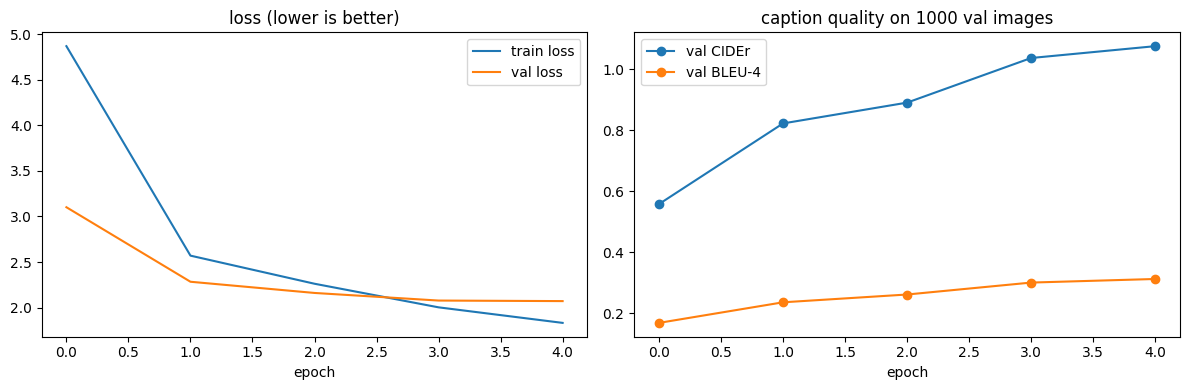

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(history.epoch, history.train_loss, label='train loss')
axs[0].plot(history.epoch, history.val_loss, label='val loss')
axs[0].set_xlabel('epoch'); axs[0].legend(); axs[0].set_title('loss (lower is better)')
axs[1].plot(history.epoch, history.val_cider, marker='o', label='val CIDEr')
axs[1].plot(history.epoch, history.val_bleu4, marker='o', label='val BLEU-4')
axs[1].set_xlabel('epoch'); axs[1].legend(); axs[1].set_title(f'caption quality on {len(eval_ids)} val images')
plt.tight_layout(); plt.show()

# 8. Final evaluation on all 5,000 val2017 images
Validation perplexity here is **not comparable** to the original notebook's 8.0: the validation images are new to the model, and the loss now also includes predicting the first word. Compare runs on CIDEr / BLEU-4 instead.

In [17]:
trainer.load_best_model()
model = trainer.model.eval()

for method in ['greedy', 'beam']:
    t0 = time.time()
    preds = caption_images(model, all_val_ids, method)
    sc = score_captions(preds, val_refs)
    log_result(exp=EXP_NAME, decoding=method, beam_size=cfg.beam_size if method == 'beam' else 1,
               n_images=len(preds), train_captions=len(train_df), epochs=len(history),
               eval_minutes=round((time.time() - t0) / 60, 1), **sc)
    print(method, sc)

json.dump(preds, open(cfg.out_dir / 'val2017_beam_predictions.json', 'w'))
pd.read_csv(cfg.results_csv)

captioning (greedy):   0%|          | 0/79 [00:00<?, ?it/s]

greedy {'bleu1': 0.7277396913992047, 'bleu4': 0.3100802134927433, 'cider': 1.0220883131991236}


captioning (beam):   0%|          | 0/79 [00:00<?, ?it/s]

beam {'bleu1': 0.7284931451037763, 'bleu4': 0.3228733046969587, 'cider': 1.0575914419843213}


,time,exp,decoding,beam_size,n_images,eval_minutes,bleu1,bleu4,cider,device,naive_ms,cached_ms,speedup,identical_captions,train_captions,epochs
0,2026-11-19 05:20,E0_original,greedy,1.0,5000,2.0,0.661451,0.234718,0.786806,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-11-19 05:21,E1_original_beam,beam,3.0,5000,1.6,0.646651,0.244876,0.811329,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-11-19 05:21,E2_original_speed,NaN,NaN,50,NaN,NaN,NaN,NaN,cuda,263.2,97.8,2.69,1.0,NaN,NaN
3,2026-11-19 05:22,E2_original_speed,NaN,NaN,10,NaN,NaN,NaN,NaN,cpu,3360.8,624.1,5.38,1.0,NaN,NaN
4,2026-11-19 08:25,E3_fixed_compare,greedy,1.0,5000,1.0,0.727740,0.310080,1.022088,NaN,NaN,NaN,NaN,NaN,150000.0,5.0
5,2026-11-19 08:27,E3_fixed_compare,beam,3.0,5000,1.5,0.728493,0.322873,1.057591,NaN,NaN,NaN,NaN,NaN,150000.0,5.0


In [18]:
for dev, n in [('cuda', 50), ('cpu', 10)]:
    if dev == 'cuda' and not torch.cuda.is_available():
        continue
    b = benchmark_decoding(model, all_val_ids[:n], dev)
    log_result(exp=f'{EXP_NAME}_speed', **b)
    print(b)
model.to(cfg.device)
pd.read_csv(cfg.results_csv)

{'device': 'cuda', 'n_images': 50, 'naive_ms': 291.8, 'cached_ms': 108.7, 'speedup': 2.68, 'identical_captions': 1.0}
{'device': 'cpu', 'n_images': 10, 'naive_ms': 3809.2, 'cached_ms': 690.5, 'speedup': 5.52, 'identical_captions': 1.0}


,time,exp,decoding,beam_size,n_images,eval_minutes,bleu1,bleu4,cider,device,naive_ms,cached_ms,speedup,identical_captions,train_captions,epochs
0,2026-11-19 05:20,E0_original,greedy,1.0,5000,2.0,0.661451,0.234718,0.786806,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-11-19 05:21,E1_original_beam,beam,3.0,5000,1.6,0.646651,0.244876,0.811329,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-11-19 05:21,E2_original_speed,NaN,NaN,50,NaN,NaN,NaN,NaN,cuda,263.2,97.8,2.69,1.0,NaN,NaN
3,2026-11-19 05:22,E2_original_speed,NaN,NaN,10,NaN,NaN,NaN,NaN,cpu,3360.8,624.1,5.38,1.0,NaN,NaN
4,2026-11-19 08:25,E3_fixed_compare,greedy,1.0,5000,1.0,0.727740,0.310080,1.022088,NaN,NaN,NaN,NaN,NaN,150000.0,5.0
5,2026-11-19 08:27,E3_fixed_compare,beam,3.0,5000,1.5,0.728493,0.322873,1.057591,NaN,NaN,NaN,NaN,NaN,150000.0,5.0
6,2026-11-19 08:27,E3_fixed_compare_speed,NaN,NaN,50,NaN,NaN,NaN,NaN,cuda,291.8,108.7,2.68,1.0,NaN,NaN
7,2026-11-19 08:28,E3_fixed_compare_speed,NaN,NaN,10,NaN,NaN,NaN,NaN,cpu,3809.2,690.5,5.52,1.0,NaN,NaN


# 9. Sample predictions

captioning (greedy):   0%|          | 0/1 [00:00<?, ?it/s]

captioning (beam):   0%|          | 0/1 [00:00<?, ?it/s]

Exception in thread QueueFeederThread:
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 289, in _feed
    queue_sem.release()
    ~~~~~~~~~~~~~~~~~^^
ValueE

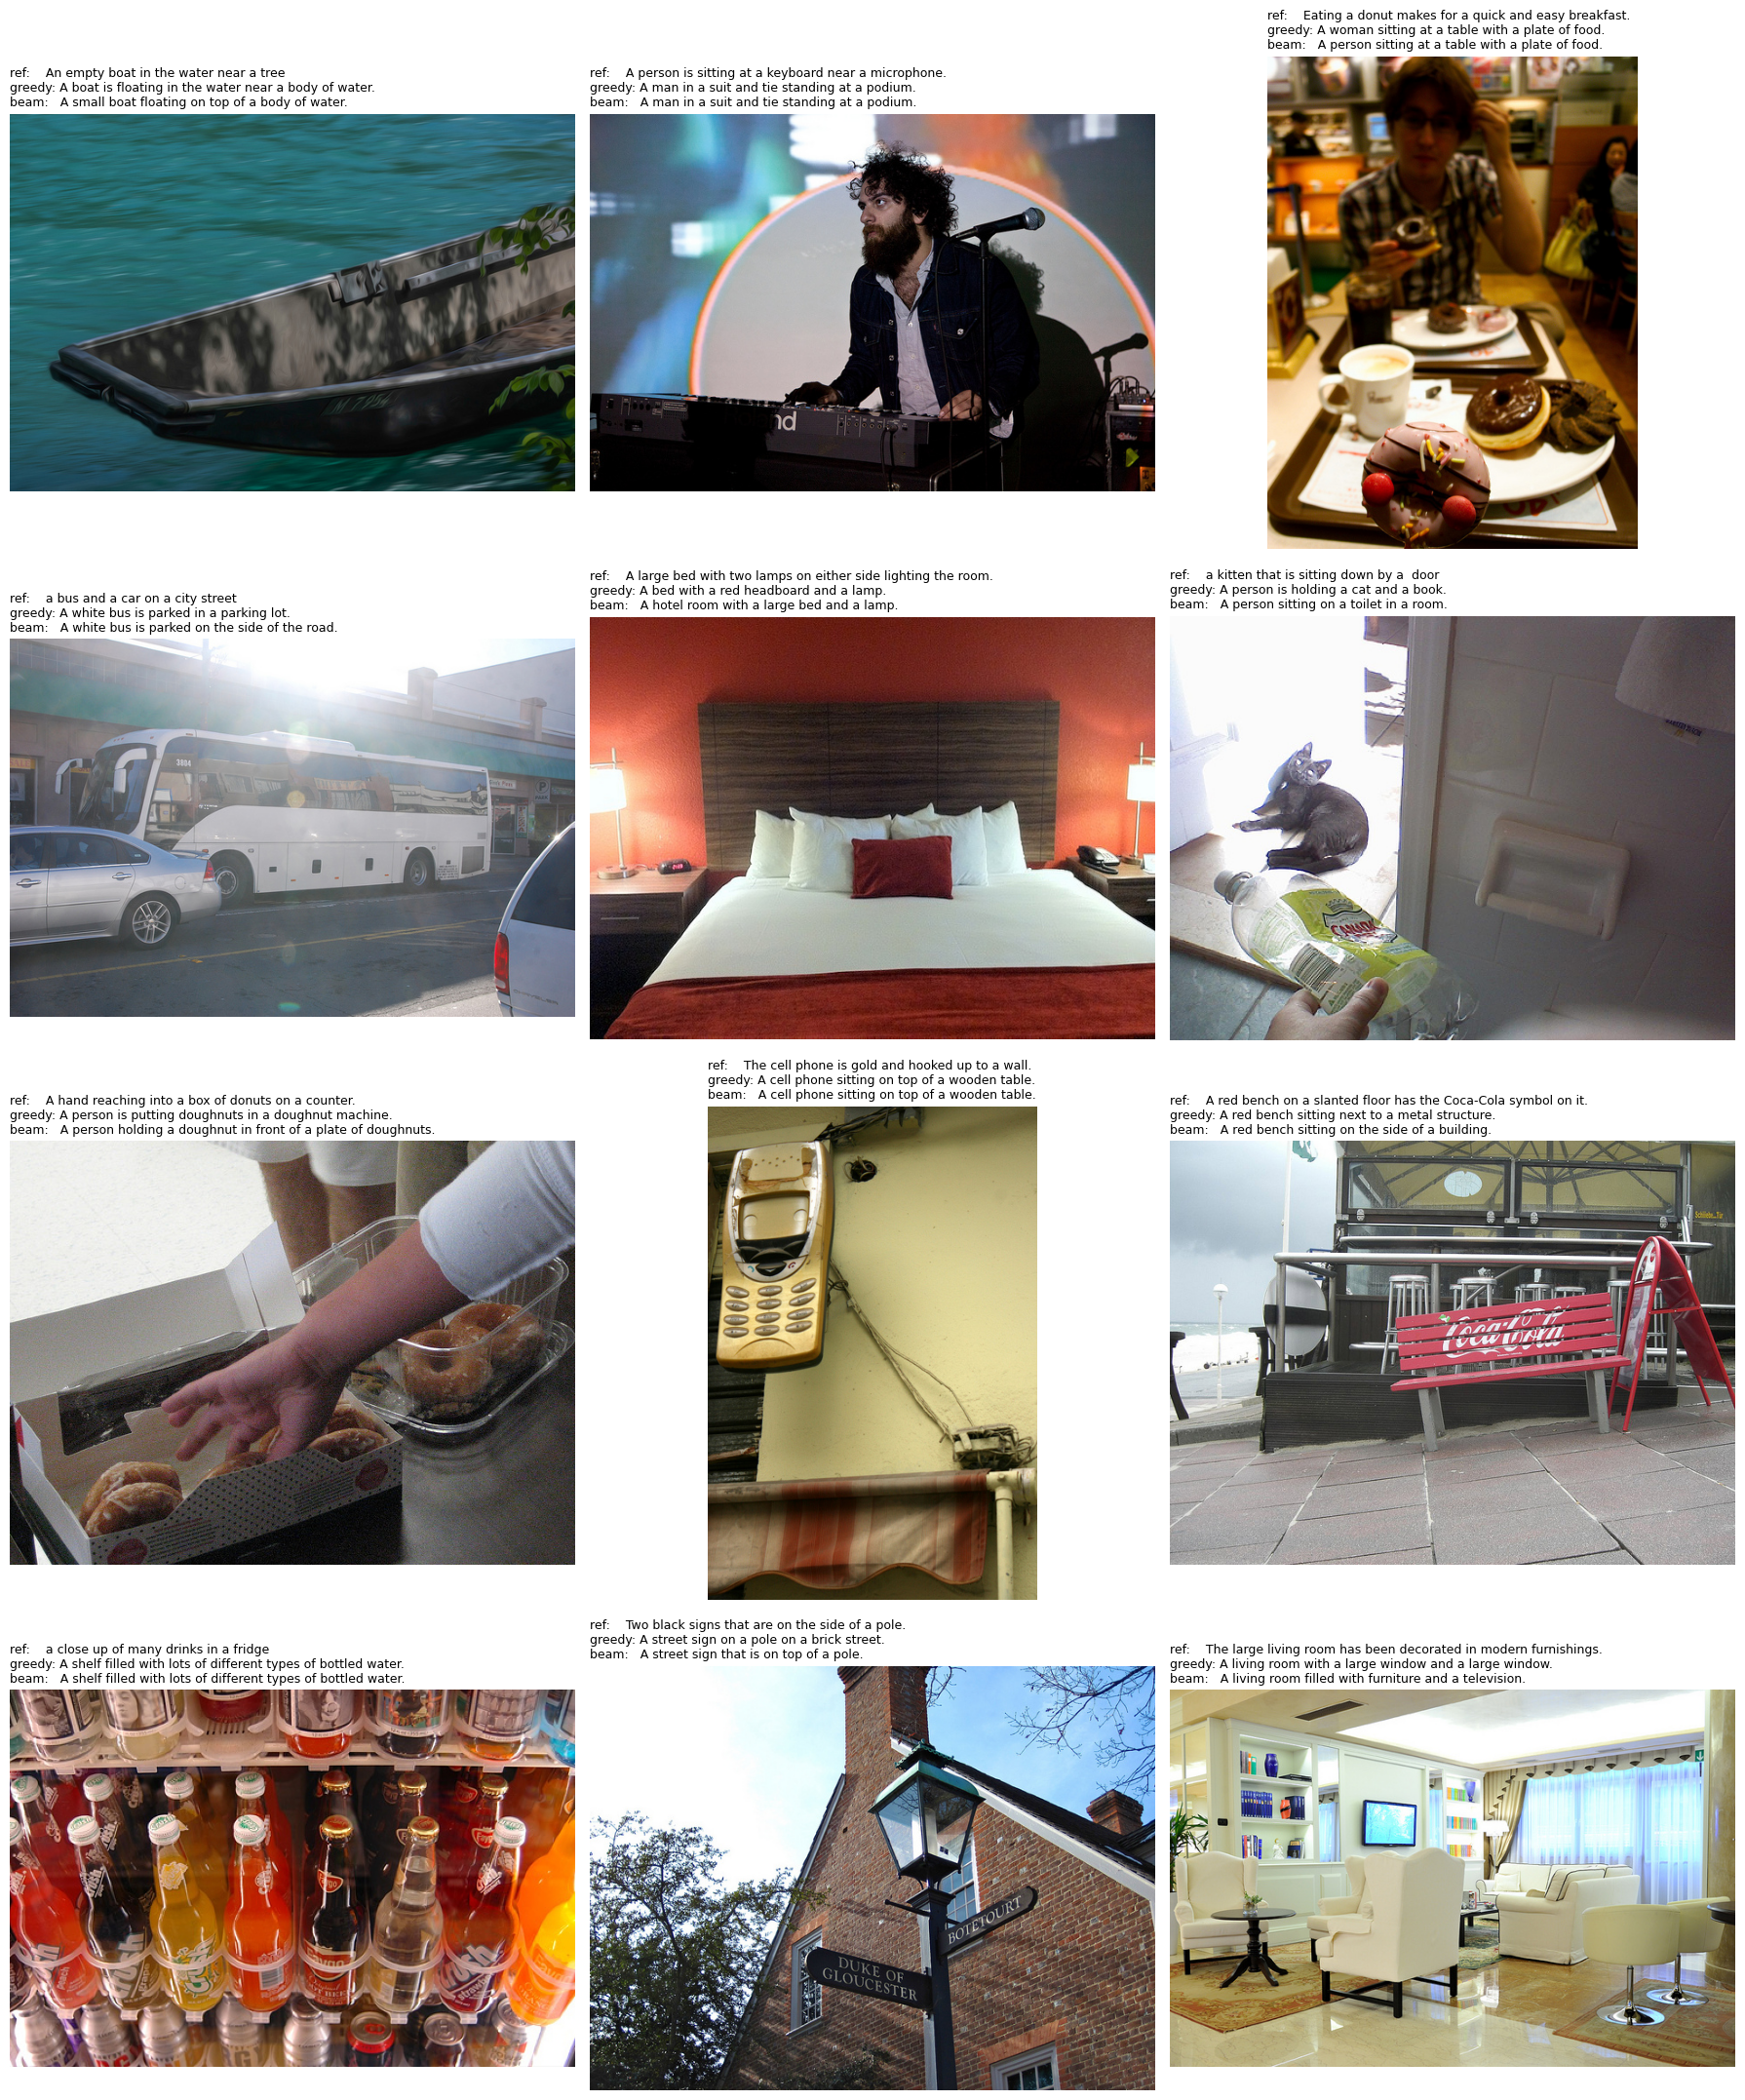

In [19]:
sample_ids = random.Random(0).sample(all_val_ids, min(12, len(all_val_ids)))
greedy_p = caption_images(model, sample_ids, 'greedy')
beam_p = caption_images(model, sample_ids, 'beam')
fig, axs = plt.subplots(4, 3, figsize=(18, 22))
for ax, i in zip(axs.flat, sample_ids):
    ax.imshow(Image.open(val_id2path[i]).convert('RGB')); ax.axis('off')
    ax.set_title(f'ref:    {val_refs[i][0]}\ngreedy: {greedy_p[i]}\nbeam:   {beam_p[i]}', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

# 10. Export for the Hugging Face Space
Saves fp16 weights without the unused attention-mask buffers (~480 MB instead of ~1 GB). In the Space, load with `strict=False` and use `generate` / `generate_beam` from this notebook.

In [20]:
export = {k: v.half() for k, v in model.state_dict().items() if not k.endswith('.attn.mask')}
torch.save(export, cfg.out_dir / 'captioner_fp16.pt')
print(f"{(cfg.out_dir / 'captioner_fp16.pt').stat().st_size / 1e6:.0f} MB")
# in the Space:
#   model = VisionGPT2Model(model_config)
#   missing, unexpected = model.load_state_dict(torch.load('captioner_fp16.pt', map_location='cpu'), strict=False)
#   assert all(k.endswith('.attn.mask') for k in missing) and not unexpected
#   model = model.float().eval()

555 MB
